# 第II部：Euler方程式の古典的数値解法

**比較対象：LF、LW（Richtmyerの2段階法）**

線形移流・Burgersとの関係を整理し、3成分の保存則をLF・LWで計算します。

[I 移流・Burgers](01_advection_burgers.ipynb) · [II Eulerの古典的解法](02_euler_classical.ipynb) · [III 近似リーマンソルバー](03_euler_riemann_solvers.ipynb) · [IV 空間再構築](04_spatial_reconstruction.ipynb) · [V 時間積分](05_time_integration.ipynb)

数値流束・空間再構築・時間積分は区別して比較します。LWは滑らかな解で2次精度です。
第III部で数値流束、第IV部で空間再構築、第V部で時間積分をそれぞれ比較します。

**この部で最初に理解すること**

第I部では一つの量$q$を更新しました。ここでは、一つのセルにつき**質量・運動量・全エネルギーに対応する三つの平均値**を保存します。三つを別々の問題として解くのではなく、同じ流体の状態として同時に更新します。

最初は、保存変数と基本変数の違い、流束に含まれる圧力の役割、Sod問題で現れる三つの波を確認してください。固有値の計算や厳密解の細部は、それらの意味が分かってから読むと追いやすくなります。

この部のLF・LWは、リーマン問題の波を明示的に組み立てずに境界流束を作る比較対象です。第III部のGodunov型スキームへ進む前に、同じ保存則でも流束の作り方で拡散や振動が変わることを学びます。

## 0. 設定と実行方法

リポジトリ一式を取得し、`notebooks/` と `src/` の配置を保ってください。
計算は `src/euler1d_core.py`、比較・描画は `src/euler1d_study.py` を使用します。
設定セルを確認し、カーネルを再起動して上から実行してください。
`run_convergence` は収束試験、`run_extras` は追加実験、`run_shu_osher` はShu–Osher問題、`run_movies` は動画です。
動画は標準で有効です。追加実験・Shu–Osherは初期設定で無効です。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/euler1d_study.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("リポジトリ一式を取得し、notebooks/ と src/ の配置を保って実行してください。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from euler1d_core import PROBLEMS, run_unit_tests
from euler1d_study import PARTS, RUN_CACHE, get_run, run_part, summarize, show_table, plot_profiles, plot_pressure_minimum, run_convergence, shu_reference, export_results, make_part_animation

### 0.1 時間発展動画の問題を選択する

設定セルの `CFG["movie_problem"]` に、次のいずれかの文字列を指定します。

| 設定する値 | 問題 | 主な観察点 |
|:--|:--|:--|
| `entropy` | 滑らかなエントロピー波の移流 | 波形の拡散・位相誤差 |
| `contact` | 移動する接触不連続面 | 接触面の数値拡散・振動 |
| `contact_static` | 静止する接触不連続面 | 静止した密度不連続の保持 |
| `sod` | Sod衝撃波管 | 衝撃波・接触不連続面・希薄波 |
| `double_rarefaction` | 二重希薄波 | 低密度・低圧力での頑健性、計算停止 |
| `lax` | Lax衝撃波管 | Sodとは異なる衝撃波条件 |
| `transonic` | 音速をまたぐ希薄波 | エントロピー補正の影響 |

`shu_osher` は数値参照解を必要とするため、この簡易動画機能の選択肢には含めません。Shu–Osherの計算・静止図は `run_shu_osher` で実行できます。

動画を無効にする場合は `CFG["run_movies"] = False` に設定してください。

In [2]:
PART = "classical"
CFG = {
    "gamma": 1.4,
    "cfl": 0.4,
    "n_basic": 200,
    "n_convergence": (100, 200, 400, 800),
    "limiter": "minmod",
    "wave_speeds": "einfeldt",
    "roe_entropy": 0.1,
    "n_shu_osher": 400,
    "n_reference": (1600, 3200),
    "reference_limiter": "mc",
    "run_convergence": True,
    "run_shu_osher": False,
    "run_extras": False,
    "run_movies": True,
    "movie_problem": "sod",  # 選択肢は直前の表を参照
    "movie_frames": 61,
    "export_results": True,
}
RUN_CACHE.clear()
RESULTS = {}
reference_fine = None
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
print(CFG)
OUTPUT_DIR = ROOT / "five_part_outputs" / PART
print("Part:", PARTS[PART]["title"])
print("Output directory:", OUTPUT_DIR)

Python: 3.11.18 NumPy: 2.4.6
{'gamma': 1.4, 'cfl': 0.4, 'n_basic': 200, 'n_convergence': (100, 200, 400, 800), 'limiter': 'minmod', 'wave_speeds': 'einfeldt', 'roe_entropy': 0.1, 'n_shu_osher': 400, 'n_reference': (1600, 3200), 'reference_limiter': 'mc', 'run_convergence': True, 'run_shu_osher': False, 'run_extras': False, 'run_movies': True, 'movie_problem': 'sod', 'movie_frames': 61, 'export_results': True}
Part: Part II: classical Euler methods
Output directory: /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/five_part_outputs/classical


**記号と表の対応**

$\bar q_i$・$\bar{\boldsymbol U}_i$はセル平均、$f$・$\boldsymbol F$は物理流束、$\widehat F$・$\widehat{\boldsymbol F}$は数値流束です。半離散式の数値流束は各時刻の値、1ステップの更新式では各段階の重みを含む時間平均の近似を指します。

$C_{\mathrm{adv}}=a\Delta t/\Delta x$は符号付きの移流Courant数、$C_{\mathrm{CFL}}=\Delta t\max(|u|+c)/\Delta x$はEuler系の最大信号速度によるCFL数です。コードの`cfl`は後者の上限設定（スカラーでは$|C_{\mathrm{adv}}|$の上限）に対応します。

$E_{\mathrm{total}}$は連続方程式の厳密解に対する平均絶対誤差、$E_{\mathrm{time}}$は同じ半離散系の時間参照解に対する誤差です。表の`L1`・`L1_rho`は、それぞれスカラー量・密度の$E_{\mathrm{total}}$に対応します。密度以外の誤差列は同じ定義を該当する基本変数へ適用します。

## 1. 移流・BurgersからEuler方程式へ

### 1.1 移流、圧縮・膨張、圧力による加速

滑らかな1次元の理想気体では、物質微分$\frac{D}{Dt}=\frac{\partial}{\partial t}+u\frac{\partial}{\partial x}$を使って

$$\frac{D\rho}{Dt}=-\rho \frac{\partial u}{\partial x},\qquad\frac{Du}{Dt}=-\frac{1}{\rho}\frac{\partial p}{\partial x},\qquad\frac{Dp}{Dt}=-\gamma p \frac{\partial u}{\partial x}$$

と書けます。密度には圧縮・膨張、速度には圧力勾配、圧力には断熱的な圧縮・膨張が作用します。
これらは滑らかな領域の基本変数表示です。**衝撃波の計算には下に示す保存形を使います。**

$u=u_0,p=p_0$が一定なら、任意の密度分布$\rho_0(x-u_0t)$はEuler方程式の解になります。
$E=p_0/(\gamma-1)+\rho u_0^2/2$も併せて与えます。エントロピー波と接触面の移流は、流体方程式の中に線形移流を見いだせる例です。[R1]

一方、$\frac{\partial u}{\partial t}+u \frac{\partial u}{\partial x}=0$というBurgers形は速度の非線形移流を分離したモデルです。
$\frac{\partial p}{\partial x}=0$を初期に置くだけでは一般に圧力勾配ゼロを保てません。形式的な無圧力極限の滑らかな速度方程式と、衝撃波を含む圧縮性気体全体を混同しないでください。

### 1.2 3つの特性速度はどこから来るか

$W=(\rho,u,p)^T$に対して

$$\frac{\partial W}{\partial t}+B(W)\frac{\partial W}{\partial x}=0,\qquad B=\begin{pmatrix}u&\rho&0\\0&u&1/\rho\\0&\gamma p&u\end{pmatrix}.$$

$$\det(B-\lambda I)=(u-\lambda)\left[(u-\lambda)^2-\frac{\gamma p}{\rho}\right]=0.$$

したがって$c=\sqrt{\gamma p/\rho}$として、固有値は$u-c,u,u+c$です。
$a$が一つのスカラー移流や、速度$q$が一つのBurgersと異なり、複数の波を区別する必要があります。[R1]

### 1.3 一様背景まわりの線形化は、3本の移流方程式になる

$(\rho_0,u_0,p_0)$を一定とし、微小擾乱について

$$w_\pm=\delta u\pm\frac{\delta p}{\rho_0c_0},\qquad w_0=\delta\rho-\frac{\delta p}{c_0^2}$$

とおくと、

$$\frac{\partial w_\pm}{\partial t}+(u_0\pm c_0)\frac{\partial w_\pm}{\partial x}=0,\qquad\frac{\partial w_0}{\partial t}+u_0\frac{\partial w_0}{\partial x}=0.$$

$w_\pm$は両方向の音響波、$w_0$は接触・エントロピー波です。$u_0=0$でも音波は伝わります。
この独立な3本への分離は**一様背景に対する線形化**の結果です。非線形Euler全体を固定変数変換で独立な3本へ分けられるという意味ではありません。

第III部のRoe法は、このような局所的な特性分解を数値流束に利用します。
LF・LWは明示的な特性分解を使わず、同じ保存形の流束を3成分のベクトルへ拡張できます。

### 1.4 保存変数の行列と基本変数の行列

滑らかな状態では、$\boldsymbol U=\boldsymbol U(\boldsymbol W)$の変換行列$J=\frac{\partial\boldsymbol U}{\partial\boldsymbol W}$を用いて、基本変数の係数行列$B$と保存形のヤコビ行列$A=\frac{\partial\boldsymbol F}{\partial\boldsymbol U}$の関係を表せます。

$$A=JBJ^{-1}.$$

密度が正の状態では変換が可能で、相似な2つの行列は同じ固有値$u-c,u,u+c$を持ちます。したがって、基本変数で見た3つの波を、保存変数でも同じ速度で記述できます。第III部のRoe法は、左右状態から作る局所的な行列について、この特性分解を使います。一様背景の線形化と、有限の左右差から作るRoe平均は、役割を区別してください。[P2, P8]

### 1.5 特性速度は何の速さか

特性速度は、小さな変化の情報が観測者に対して伝わる速さです。流速$u$と音速$c$を使うと、Euler方程式では$u-c,u,u+c$の三つがあります。例えば$u=0,c=1$なら、流体は静止していても音響的な情報は左へ速さ1、右へ速さ1で伝わります。[R1]

「左向き・右向き音響波」は流体に対しての呼び方です。観測者から見た方向は$u-c$と$u+c$の符号で決まります。$u>c$なら両方とも右へ進みます。

| 波 | 何が起こるか | 図で注目する量 |
|:--|:--|:--|
| 衝撃波 | 圧縮が急な跳びとして伝わる | 密度・圧力・速度の跳び |
| 接触不連続面 | 速度と圧力が同じで、密度が異なる二つの流体状態の境目 | 密度だけの跳び |
| 希薄波 | 流体が膨張し、状態が扇状の領域で連続的に変わる | 幅を持つ密度・圧力・速度の変化 |

三つの特性速度は、滑らかな状態の近くの波を理解するためのものです。有限の強さの衝撃波の速度を、どちらか片側の$u+c$へそのまま置き換えることはできません。衝撃波速度は、前後の状態と保存則から決まります。

次の固有値の検算は、この情報伝播の速さが係数行列から得られることを確かめる計算です。固有値の式だけを覚えるのではなく、なぜ流速の符号だけでは風上側を決められないのかと結び付けてください。

In [3]:
rho0, u0, p0 = 1.0, 0.2, 1.0
c0 = np.sqrt(CFG["gamma"] * p0 / rho0)
B = np.array([[u0, rho0, 0.0], [0.0, u0, 1.0 / rho0], [0.0, CFG["gamma"] * p0, u0]])
L = np.array([[0.0, 1.0, -1.0 / (rho0 * c0)], [1.0, 0.0, -1.0 / c0**2], [0.0, 1.0, 1.0 / (rho0 * c0)]])
expected = np.array([u0 - c0, u0, u0 + c0])
np.testing.assert_allclose(np.sort(np.linalg.eigvals(B)), expected)
np.testing.assert_allclose(L @ B, np.diag(expected) @ L, atol=2e-14)
print("Characteristic speeds:", expected)

Characteristic speeds: [-0.98321596  0.2         1.38321596]


## 2. 保存変数と計算条件

### 2.1 共通の方程式と保存形

無粘性・断熱の理想気体を扱います。量はすべて無次元です。$E$は**単位体積当たりの全エネルギー**、$e$は**単位質量当たりの内部エネルギー**です。

$$
\frac{\partial\boldsymbol U}{\partial t}+\frac{\partial\boldsymbol F}{\partial x}=0,
\qquad
\boldsymbol U=\begin{pmatrix}\rho\\\rho u\\E\end{pmatrix},
\qquad
\boldsymbol F=\begin{pmatrix}\rho u\\\rho u^2+p\\u(E+p)\end{pmatrix}.
$$
$$
E=\frac{p}{\gamma-1}+\frac12\rho u^2,\qquad
c=\sqrt{\frac{\gamma p}{\rho}},\qquad e=\frac{p}{(\gamma-1)\rho}.
$$

特性速度は$u-c,\ u,\ u+c$です。中央の波が接触・エントロピー波を担います。[R1]

コードでは`U.shape == (N, 3)`とし、`U[:, 0]`が密度、`U[:, 1]`が運動量密度、`U[:, 2]`が全エネルギー密度です。
基本変数`W`は$(\rho,u,p)$の順です。境界流束を差し引く更新式を全方式で共有します。

$$
\overline{\boldsymbol U}^{\,n+1}_i=\overline{\boldsymbol U}^{\,n}_i-
\frac{\Delta t}{\Delta x}(\widehat{\boldsymbol F}_{i+1/2}-\widehat{\boldsymbol F}_{i-1/2}).
$$

ここで格子上の未知量は**点値ではなくセル平均**です。
一様格子上で区分一定の状態を用いる場合、以下のLF/LWの保存形実装は対応する古典的な差分更新になります。

### 2.2 なぜ密度・速度・圧力を、そのまま三つ保存しないのか

物理状態を考えるには、密度$\rho$、速度$u$、圧力$p$が便利です。これらを**基本変数**と呼びます。一方、境界を通る出入りから収支を計算するには、密度$\rho$、運動量密度$\rho u$、全エネルギー密度$E$を使います。こちらが**保存変数**です。[R1]

$$\boldsymbol W=(\rho,u,p)^T,\qquad \boldsymbol U=(\rho,\rho u,E)^T.$$

$T$は三つの成分を縦に並べる記号です。ここで$E$は単位体積当たりで、単位質量当たりの内部エネルギー$e$とは異なります。理想気体では

$$E=\frac{p}{\gamma-1}+\frac12\rho u^2.$$

例えば説明用に$\rho=1,u=2,p=1,\gamma=1.4$とすると、内部エネルギー密度は2.5、運動エネルギー密度は2なので、$\boldsymbol U=(1,2,4.5)^T$です。数値更新後には、$u=(\rho u)/\rho$と状態方程式から圧力を求め直します。速度や圧力を好きな値に独立に変更すると、運動量やエネルギーの収支も変わってしまいます。

セルに保存した$\bar{\boldsymbol U}$から求める$\boldsymbol W(\bar{\boldsymbol U})$は、セル平均を代表する基本変数です。非線形な変換のため、連続解の基本変数を直接平均したものとは一般に一致しません。

### 2.3 圧力は流束にも現れる

質量流束$\rho u$は、密度に流速を掛けたものです。運動量流束$\rho u^2+p$には、物質が運ぶ運動量に加えて、圧力による力の寄与があります。エネルギー流束$u(E+p)$には、全エネルギーの輸送と圧力仕事が含まれます。[R1]

したがって、流体が静止していても、圧力差があれば次の瞬間には動き始めます。Euler方程式は「三つの量を流速$u$で運ぶだけの式」ではありません。

### 2.4 初期条件と境界条件を区別する

**初期条件**は計算開始時刻の領域全体の状態、**境界条件**は計算中に領域の端をどう扱うかです。内部のセル境界と、計算領域の外端も区別します。

周期境界では右端の続きが左端になります。流出境界では、この実装は端のセルの値を外側へコピーします。**ゴーストセル**は、このような外側の値を一時的に置き、端のセルでも内部と同じ計算式を使えるようにする補助セルです。物理領域のセル数には含めません。

保存形でも、開いた境界から物質が出れば領域内の質量は減ります。そこで、表では「領域内の変化」だけでなく「境界を通った量」も含めて収支を調べます。

### 2.5 共通のテスト問題と初期条件

すべて$\gamma=1.4$の設定です。$W=(\rho,u,p)$と表記します。
矩形波のセル内占有率と正弦波のセル平均を解析的に求め、格子点で初期条件を単純にサンプルする誤差を避けます。

| キー | 領域・時刻 | 初期条件の要点 | 境界 |
|:--|:--|:--|:--|
| `entropy` | $[0,1],\ t=1$ | $\rho=1+0.2\sin(2\pi x),\ u=p=1$ | 周期 |
| `contact` | $[0,1],\ t=0.25$ | $0.25\le x<0.45$で$\rho=2$、他は1。$u=p=1$ | 周期 |
| `contact_static` | $[0,1],\ t=0.25$ | 同じ矩形密度、$u=0,\ p=1$ | 周期 |
| `sod` | $[0,1],\ x_0=0.5,\ t=0.2$ | $W_L=(1,0,1),\ W_R=(0.125,0,0.1)$ | 流出 |
| `double_rarefaction` | $[-0.5,0.5],\ x_0=0,\ t=0.15$ | $W_L=(1,-2,0.4),\ W_R=(1,2,0.4)$ | 流出 |
| `shu_osher` | $[-5,5],\ x_0=-4,\ t=1.8$ | 左は衝撃波通過後、右は$\rho=1+0.2\sin(5x),\ u=0,\ p=1$ | 左固定流入・右流出 |
| `transonic` | $[0,1],\ x_0=0.3,\ t=0.2$ | $W_L=(1,0.75,1),\ W_R=(0.125,0,0.1)$ | 流出 |
| `lax` | $[-0.5,0.5],\ x_0=0,\ t=0.14$ | $W_L=(0.445,0.698,3.528),\ W_R=(0.5,0,0.571)$ | 流出 |

SodとShu–Osherの設定は文献・公式テスト例と対応します。[R4, R5]
Shu–Osherの左状態は$\rho_L=27/7,\ u_L=20\sqrt{1.4}/9,\ p_L=31/3$とし、よく用いられる小数値の丸めを避けています。
$\gamma$を変更した場合、この左状態が同じMach数の衝撃波に対応するとは限りません。

流出境界は端のセルをゴーストセルにコピーする簡単な条件で、完全な無反射境界ではありません。
指定した終了時刻では、Sodなどのリーマン問題の主要波面は境界に達しません。

Shu–Osher・Lax・音速をまたぐ希薄波は追加実験で扱います。Laxはここでは**問題の名称**で、LF/LWだけを使うという意味ではありません。

### 2.6 厳密解と比較の基準

エントロピー波と接触不連続面は、そのまま速度$u$で平行移動します。
Sod・二重希薄波・追加のリーマン問題は、星領域の圧力$p_*$を

$$
f_L(p_*)+f_R(p_*)+u_R-u_L=0
$$

から二分法で求めます。希薄波と衝撃波で分岐する$f_K$、自己相似変数$\xi=(x-x_0)/t$における解をコードに明示しています。[R1]
ここでの「厳密解」は厳密なリーマン解の構造に基づく数値評価で、非線形方程式の解法と数値積分の許容誤差は残ります。

**誤差は保存変数をセル平均した厳密解と比較します。** 波面の位置で積分区間を分割してからGauss積分するので、不連続を横切る単純な台形積分は使いません。
速度と圧力の比較基準は$W(\overline U_{\rm exact})$です。これは一般に$\overline{W(U_{\rm exact})}$とは異なります。

図には見やすさのため点値の厳密解を実線で示しますが、誤差表にはセル平均基準を使います。
Shu–Osherは厳密解を用いず、後で別に高解像度の**数値参照解**を計算します。

この実装は**物理的な真空を含むリーマン解には対応していません**。
真空条件$u_R-u_L\ge2(c_L+c_R)/(\gamma-1)$を検出すると明示的に停止します。
ここで使う二重希薄波問題は真空条件を満たさず、中央の密度・圧力は正です。

### 2.7 時間刻み・破綻・保存則

時間刻みは各計算で

$$
\Delta t=C_{\rm CFL}\frac{\Delta x}{\max_i(|u_i|+c_i)}
$$

から求めます。**共通なのはCFL数と選択規則であり、時々刻々の$\Delta t$が全方式で同じとは限りません。**
終端で極端に短い最後のステップだけを取ると、LFでは$\Delta x/\Delta t$が急増します。
これを避けるため、残り時間がCFL上限の2ステップ以内になったら残りを1または2等分します。この規則は全方式に共通です。

非周期境界では領域内の総量が変化しても保存則違反とは限りません。$Q=\sum_iU_i\Delta x$として

$$
R_Q=Q(t)-Q(0)-\int_0^t(F_{\rm left}^*-F_{\rm right}^*)\,dt'
$$

を測定します。この部では、実際の1ステップ更新に使う境界流束から保存収支を求めます。
表の`balance_max`は質量・運動量・全エネルギーの$|R_Q|$の最大値で、無次元の絶対残差です。
保存残差が小さいことだけで解の精度がよいとは判断できません。

`failed`の場合、`t_reached`は**最後に受理した時刻**です。
`failure_trial_end`は失敗した試行ステップの終端時刻で、中間段階での失敗なら実際の検出段階は`failure_reason`に表示されます。
失敗した計算の最終時刻誤差は計算しません。

### 2.8 評価指標

密度の誤差は、領域長$L$で規格化した平均$L_1$誤差

$$
E_{\mathrm{total}}(\rho)=\frac1L\sum_i\Delta x\,|\overline\rho_i-\overline\rho_{i,{\rm exact}}|
$$

です。滑らかな周期波については、基本Fourierモードの振幅比`amp_ratio`と位相誤差`phase_rad`も測定します。
接触面の`rho_overshoot`は$\max(\rho)-2$の正の部分、`rho_undershoot`は$1-\min(\rho)$の正の部分です。
`mixed_length`は$1.1<\rho<1.9$のセル幅の合計で、二つの遷移領域と振動の影響を含む補助指標です。単一の接触面の厳密な10–90%幅ではありません。

図は岡部・伊藤パレット、英語ラベル、線種とマーカーの併用に統一します。

### 2.9 計算本体の自己検証
9グループの基本検証を実行します。これは基本的な回帰テストであり、任意の初期条件での正確さ・正値性を保証するものではありません。

In [4]:
checks = run_unit_tests(CFG["gamma"])
for i, name in enumerate(checks, 1):
    print(f"PASS {i}: {name}")
print("Validation groups:", len(checks))

PASS 1: primitive/conserved round trip
PASS 2: F*(U,U) = F(U), all six solvers
PASS 3: symmetric-speed HLL equals LLF
PASS 4: stationary contact: Roe, HLLC, and Richtmyer LW
PASS 5: periodic conservation, all six solvers
PASS 6: MUSCL/SSP-RK2 periodic conservation
PASS 7: Sod star pressure and velocity
PASS 8: exact-solution quadrature and positive reference states
PASS 9: nonperiodic boundary-flux budget
Validation groups: 9


## 3. LFとLWの数値解法

**問い：数値拡散による「なまり」と、数値分散による「振動」はどのように違うか。**

古典的LFの数値流束は
$$
\widehat F_{i+1/2}=\frac{F_i+F_{i+1}}2-\frac{\Delta x}{2\Delta t}(U_{i+1}-U_i)
$$
です。係数に$\Delta t$が含まれる点を、後のLLF (Rusanov)との比較で確認します。

ここでのLWはRichtmyerの2段階法です。
$$
U^{n+1/2}_{i+1/2}=\frac{U_i^n+U_{i+1}^n}{2}-\frac{\Delta t}{2\Delta x}(F_{i+1}^n-F_i^n),\qquad
\widehat F_{i+1/2}=F(U^{n+1/2}_{i+1/2}).
$$
滑らかな解での精度と、不連続付近での数値振動を別々の問題で観察します。
「古典的」は学習上の位置づけであり、LWが1次精度という意味ではありません。

### 3.1 LF・LWでは、どの操作を比較するのか

両方とも、境界流束を計算して、その差からセル平均を更新します。**LF**は左右の物理流束の平均に、状態の差をならす散逸項を加えます。**RichtmyerのLW**は、境界の状態を半時間ステップ先へ予測し、その状態の物理流束を使います。

ここでの「散逸」は物理的な粘性を新たに方程式へ入れる意味ではありません。離散化により生じる、細かな構造をならす作用です。LFはその作用を観察しやすく、LWは滑らかな波での精度と不連続近傍の振動を観察しやすい比較例です。

LWの「2段階」は、この予測と更新を指します。第V部のSSP-RK2と同じアルゴリズムではありません。また、ここでのLWを高次の時間積分法へ単純に差し替える比較は行いません。

### 3.2 Richtmyerの2段階法を使う理由

非線形の方程式へLWの時間Taylor展開を直接適用すると、流束のヤコビ行列$A=\frac{\partial\boldsymbol F}{\partial\boldsymbol U}$が現れます。ここでは境界の半時刻状態を予測して物理流束を評価するRichtmyer型を使い、ヤコビ行列を明示的に実装する手間を避けます。線形移流では通常のLW更新と一致しますが、非線形Euler方程式では具体的にどのLW型更新を使うかの区別が必要です。[P8, P9]

### 3.3 滑らかなエントロピー波

1周後の波形を厳密解と比較します。振幅の減衰・位相のずれを見ます。LWの滑らかな解に対する精度は、この問題で評価します。

Part II: classical Euler methods | entropy: LF=ok, LW (Richtmyer)=ok


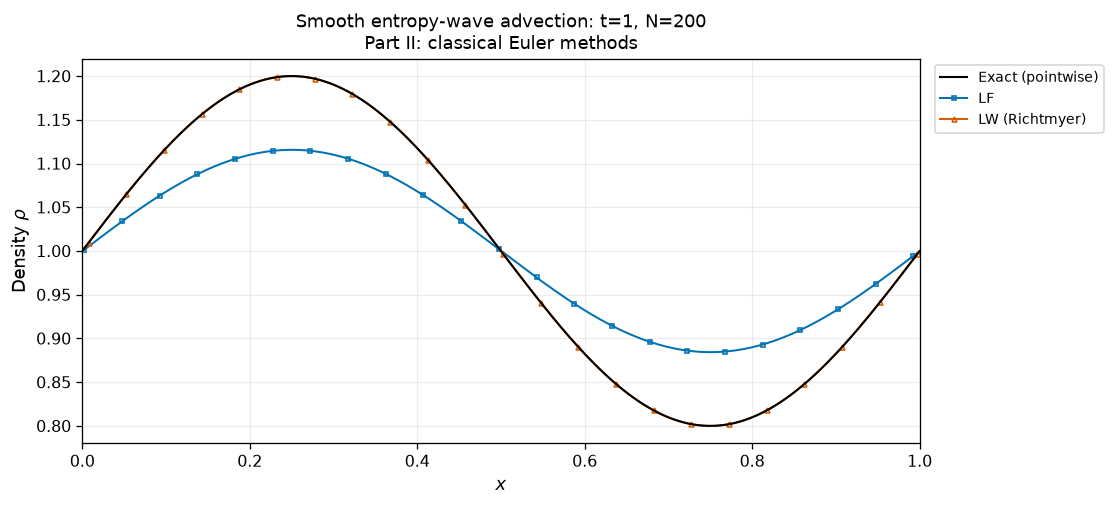

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
LF,200,1,ok,1,0.05367,0.8843,1,1.11e-15
LW (Richtmyer),200,2,ok,1,0.0001277,0.8,1,1.776e-15


[{'problem': 'entropy',
  'solver': 'LF',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 1.0,
  't_target': 1.0,
  'steps': 1144,
  'seconds': 0.5517027409999997,
  'rho_min': 0.8843211411231706,
  'p_min': 0.9999999999999991,
  'balance_max': 1.1102230246251565e-15,
  'mass_balance': np.float64(-6.661338147750939e-16),
  'momentum_balance': np.float64(-1.1102230246251565e-15),
  'energy_balance': np.float64(4.440892098500626e-16),
  'L1_rho': np.float64(0.053670709834754096),
  'L1_u': np.float64(3.4139358007223566e-16),
  'L1_p': np.float64(3.6692870963861425e-16),
  'amp_ratio': 0.5784723929711725,
  'phase_rad': -0.0020046200426243727,
  'rho_overshoot': nan,
  'rho_undershoot': nan,
  'mixed_length': nan,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'LF'},
 {'problem': 'entropy',
  'solver': 

In [5]:
RESULTS[("classical", "entropy")] = run_part("classical", "entropy", CFG)
runs = RESULTS[("classical", "entropy")]
plot_profiles(runs, fields=('rho',), logarithmic=False, title_suffix=PARTS["classical"]["title"])
summarize(runs)

### 3.4 なぜスカラー移流よりLFのなまりが大きいのか

第I部の線形移流は速度$a$が一つだけでした。Euler方程式では最も速い信号に合わせて

$$\Delta t=C_{\mathrm{CFL}}\frac{\Delta x}{\max_i(|u_i|+c_i)}$$

と刻みます。一方、この密度のエントロピー波は$u=1$で運ばれます。その波に対する実効Courant数は

$$C_{\mathrm{adv}}=\frac{u\Delta t}{\Delta x}$$

で、標準設定では約0.17〜0.18です。設定値$C_{\mathrm{CFL}}=0.4$とは異なります。

古典的LFの主要な数値拡散係数は$\nu_{\mathrm{LF}}=\Delta x^2(1-C_{\mathrm{adv}}^2)/(2\Delta t)$です。刻みを小さくすると1ステップの平均化を多数回行うことになり、LFの振幅減衰は大きくなります。スカラー正弦波では振幅比が約0.81、ここでは約0.58となる結果を、この違いから読み解けます。

**同じ格子で同じ移流距離$\ell=|u|T$を比較する**と、一次風上＋前進Eulerの主要な拡散の蓄積は

$$\nu_{\mathrm{up}}T=\frac{\Delta x\ell}{2}(1-|C_{\mathrm{adv}}|)$$

です。十分に解像された滑らかな波では、実効Courant数が小さいほど減衰が大きくなります。重要なのは速度そのものではなく、Courant数と移流距離です。200セルの正弦波を1周期動かす例では、一次風上の振幅比は約0.94から0.92へ変わり、LFの変化より小さくなります。次の表は一定のCourant数を用いた線形増幅率による見積りです。状態に応じて刻む上のEuler計算とは同一条件ではないため、傾向と大きさを比較します。

静止接触面は別に扱います。Roe・HLLCは接触波の速度$u=0$を識別して保持できますが、LFは隣接セルの平均化を続けます。これは「動かない波だからすべての方法でなまらない」という意味ではありません。[P2, P8]

In [6]:
import review_experiments as review
courant_rows = review.courant_amplitudes(n=CFG["n_basic"])
if CFG["export_results"]:
    review.write_rows(courant_rows, OUTPUT_DIR / "courant_amplitudes.json")

method,C_adv,N,distance,amplitude_ratio
Upwind,0.4,200,1,0.9425
LF,0.4,200,1,0.8128
Upwind,0.17,200,1,0.9213
LF,0.17,200,1,0.5689


### 3.5 静止する接触面

LWがこの特別な静止状態を保てても、移動する不連続面で非振動になるとは限りません。次の問題と対にして読んでください。

Part II: classical Euler methods | contact_static: LF=ok, LW (Richtmyer)=ok


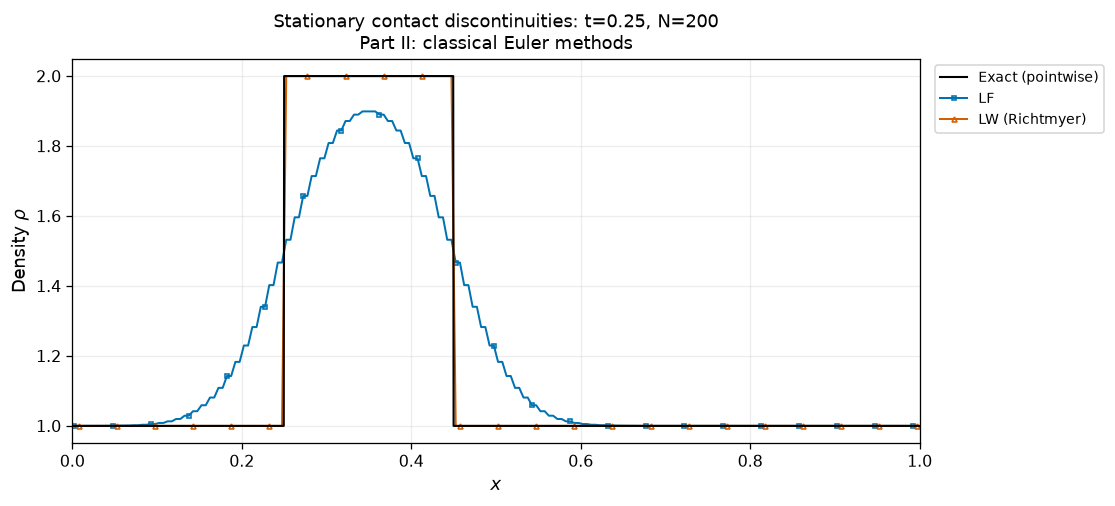

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
LF,200,1,ok,0.25,0.09687,1,1,0
LW (Richtmyer),200,2,ok,0.25,0,1,1,0


[{'problem': 'contact_static',
  'solver': 'LF',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.25,
  't_target': 0.25,
  'steps': 148,
  'seconds': 0.07498627199998964,
  'rho_min': 1.0000000000173785,
  'p_min': 1.0,
  'balance_max': 0.0,
  'mass_balance': np.float64(0.0),
  'momentum_balance': np.float64(0.0),
  'energy_balance': np.float64(0.0),
  'L1_rho': np.float64(0.0968739349514683),
  'L1_u': np.float64(0.0),
  'L1_p': np.float64(0.0),
  'amp_ratio': nan,
  'phase_rad': nan,
  'rho_overshoot': 0.0,
  'rho_undershoot': 0.0,
  'mixed_length': 0.36,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'LF'},
 {'problem': 'contact_static',
  'solver': 'LW',
  'order': 2,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_rea

In [7]:
RESULTS[("classical", "contact_static")] = run_part("classical", "contact_static", CFG)
runs = RESULTS[("classical", "contact_static")]
plot_profiles(runs, fields=('rho',), logarithmic=False, title_suffix=PARTS["classical"]["title"])
summarize(runs)

### 3.6 移動する接触面

密度の矩形分布について、LFの平滑化とLWのovershoot/undershootを区別します。正確な移流位置を保つことと、値の範囲を守ることも別の検査です。

Part II: classical Euler methods | contact: LF=ok, LW (Richtmyer)=ok


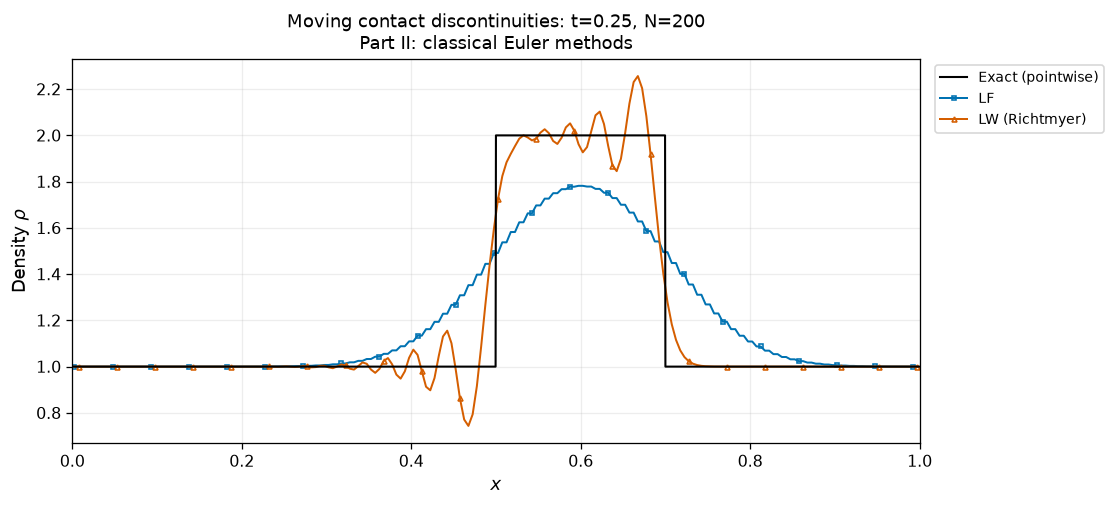

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
LF,200,1,ok,0.25,0.129,1,1,2.22e-16
LW (Richtmyer),200,2,ok,0.25,0.04183,0.7436,1,4.441e-16


[{'problem': 'contact',
  'solver': 'LF',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.25,
  't_target': 0.25,
  'steps': 273,
  'seconds': 0.13587875900000768,
  'rho_min': 1.0000007119981804,
  'p_min': 0.9999999999999992,
  'balance_max': 2.220446049250313e-16,
  'mass_balance': np.float64(-2.220446049250313e-16),
  'momentum_balance': np.float64(0.0),
  'energy_balance': np.float64(0.0),
  'L1_rho': np.float64(0.12899789011864454),
  'L1_u': np.float64(2.3869795029440865e-16),
  'L1_p': np.float64(2.425837308805967e-16),
  'amp_ratio': nan,
  'phase_rad': nan,
  'rho_overshoot': 0.0,
  'rho_undershoot': 0.0,
  'mixed_length': 0.41000000000000003,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'LF'},
 {'problem': 'contact',
  'solver': 'LW',
  'order': 2,
  'n': 200,
  'cfl': 0.4,
  'limiter'

In [8]:
RESULTS[("classical", "contact")] = run_part("classical", "contact", CFG)
runs = RESULTS[("classical", "contact")]
plot_profiles(runs, fields=('rho',), logarithmic=False, title_suffix=PARTS["classical"]["title"])
summarize(runs)

### 3.7 Sod衝撃波管

密度・速度・圧力を分けて描き、なまりと振動が現れる場所を記録します。

**図の読み方：** 左側の幅を持つ滑らかな変化が希薄波です。密度が跳ぶ場所のうち、圧力と速度がほぼ連続なものが接触面です。右側で密度・圧力・速度がともに跳ぶものが衝撃波です。密度図だけで二つの不連続を同じものとして比較しないでください。

接触面が広がっているか、衝撃波の位置が合っているか、境目の近くに余分な山谷があるかを、それぞれ別に確認します。

Part II: classical Euler methods | sod: LF=ok, LW (Richtmyer)=ok


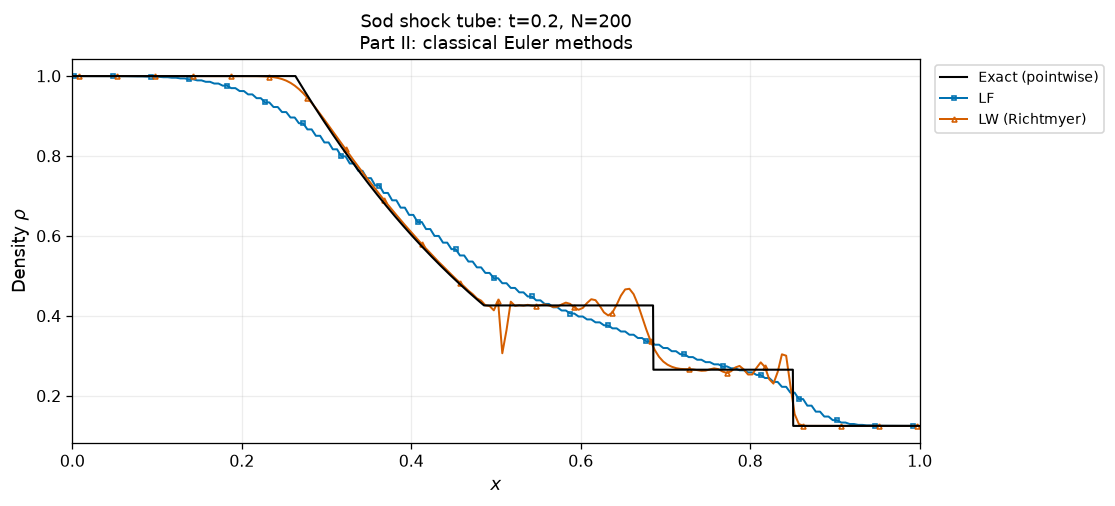

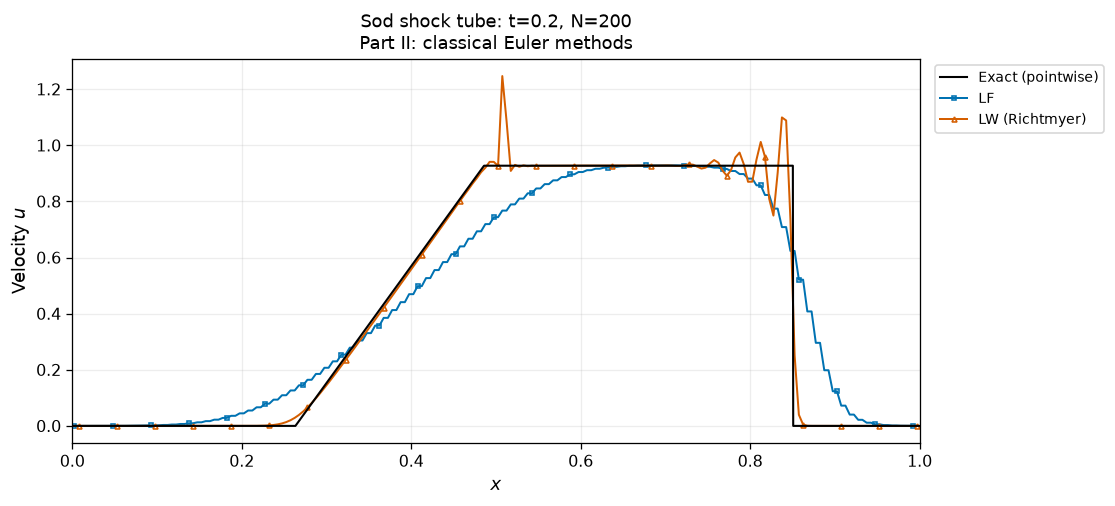

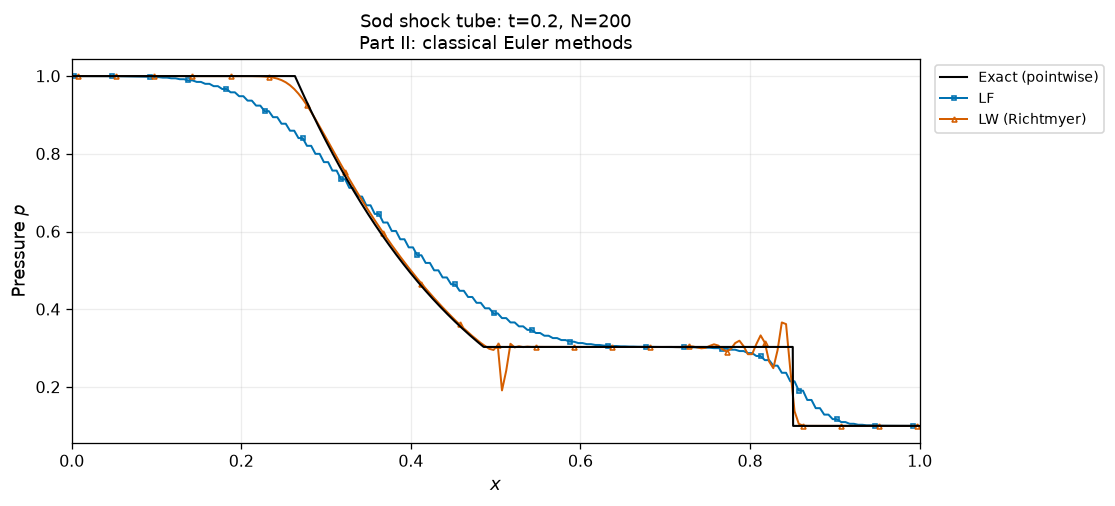

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
LF,200,1,ok,0.2,0.03259,0.125,0.1,1.3e-16
LW (Richtmyer),200,2,ok,0.2,0.007223,0.125,0.1,1.554e-15


[{'problem': 'sod',
  'solver': 'LF',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.2,
  't_target': 0.2,
  'steps': 203,
  'seconds': 0.10238229500001239,
  'rho_min': 0.12502794187068642,
  'p_min': 0.10003130785829077,
  'balance_max': 1.2995118596282392e-16,
  'mass_balance': np.float64(1.2995118596282392e-16),
  'momentum_balance': np.float64(-1.1102230246251565e-16),
  'energy_balance': np.float64(7.668681609393773e-17),
  'L1_rho': np.float64(0.03259476901710395),
  'L1_u': np.float64(0.06811660027417064),
  'L1_p': np.float64(0.033949239035117054),
  'amp_ratio': nan,
  'phase_rad': nan,
  'rho_overshoot': nan,
  'rho_undershoot': nan,
  'mixed_length': nan,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'LF'},
 {'problem': 'sod',
  'solver': 'LW',
  'order': 2,
  'n': 200,
  'cfl': 0.4,


In [9]:
RESULTS[("classical", "sod")] = run_part("classical", "sod", CFG)
runs = RESULTS[("classical", "sod")]
plot_profiles(runs, fields=('rho', 'u', 'p'), logarithmic=False, title_suffix=PARTS["classical"]["title"])
summarize(runs)

### 3.8 二重希薄波

低圧力での頑健性を調べます。停止した計算は最終時刻の図から除外し、表と圧力履歴に残します。破綻は隠さず比較結果として扱います。

Part II: classical Euler methods | double_rarefaction: LF=ok, LW (Richtmyer)=failed


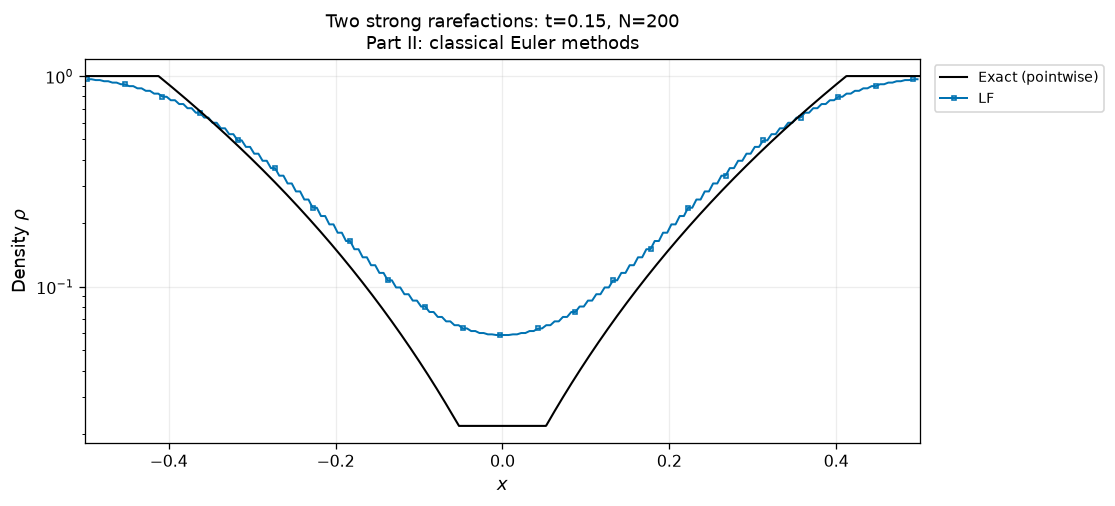

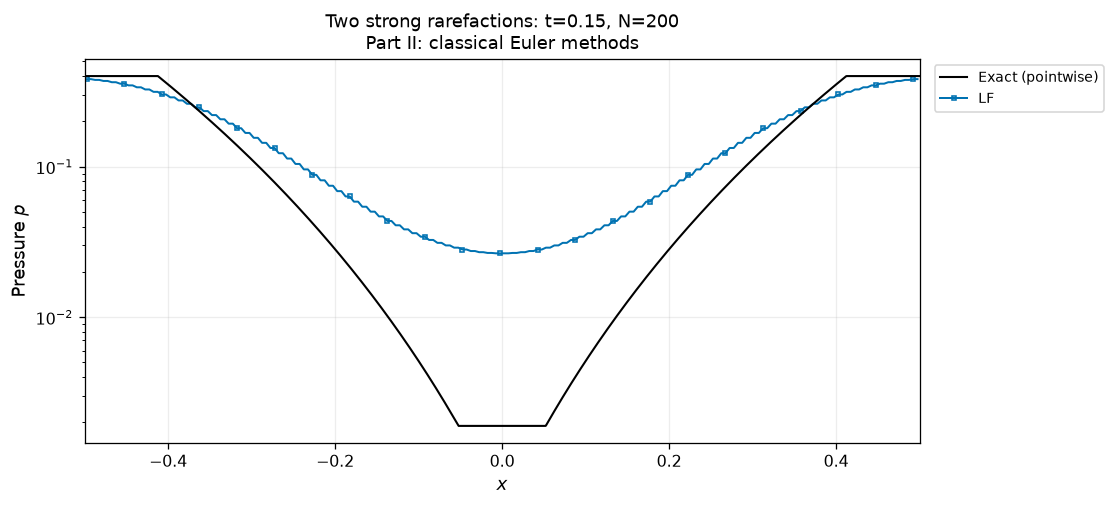

LW (Richtmyer): stopped at last accepted t=0.0014554285; rejected trial ended at t=0.0021831428.
  full-step update:  min(rho)=2.75023e-01, min(p)=-4.70761e-02


method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
LF,200,1,ok,0.15,0.05202,0.059,0.02656,2.665e-15
LW (Richtmyer),200,2,failed,0.001455,—,0.4679,0.04483,1.24e-16


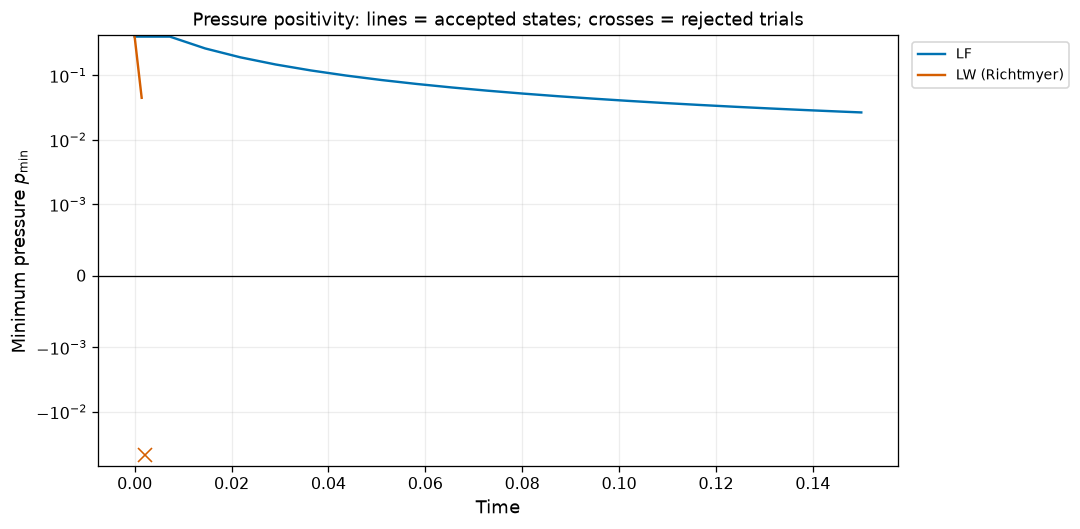

In [10]:
RESULTS[("classical", "double_rarefaction")] = run_part("classical", "double_rarefaction", CFG)
runs = RESULTS[("classical", "double_rarefaction")]
plot_profiles(runs, fields=('rho', 'p'), logarithmic=True, title_suffix=PARTS["classical"]["title"])
summarize(runs)
plot_pressure_minimum(runs)

### 3.9 滑らかな解の収束次数

LFとLWの形式的な次数は異なります。誤差の大きさだけでなく、格子を細かくしたときの変化を測ります。

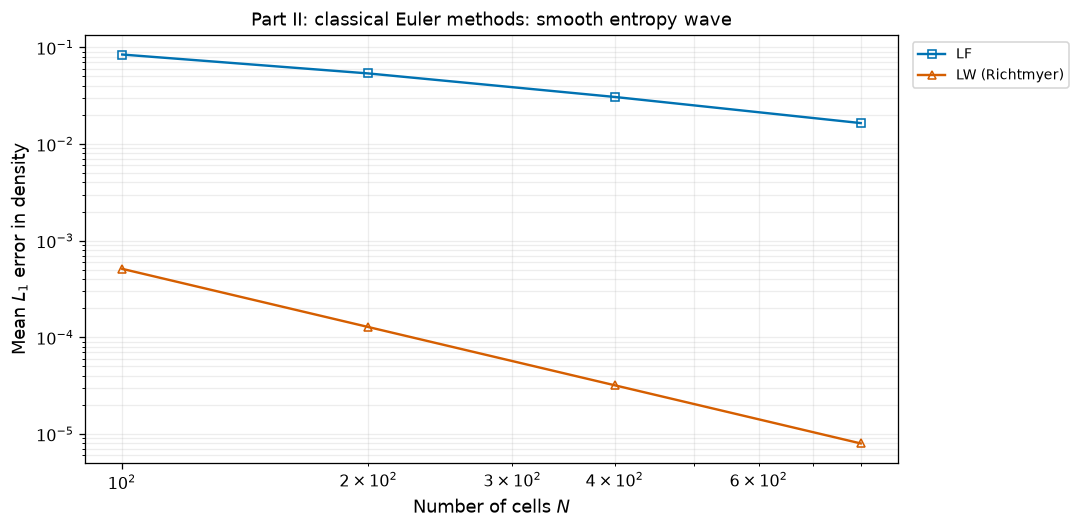

method,order,n,L1_rho,q_observed
LF,1,100,0.08422,—
LF,1,200,0.05367,0.65
LF,1,400,0.03067,0.8075
LF,1,800,0.01645,0.8982
LW (Richtmyer),2,100,0.0005106,—
LW (Richtmyer),2,200,0.0001277,2
LW (Richtmyer),2,400,3.192e-05,2
LW (Richtmyer),2,800,7.981e-06,2


In [11]:
if CFG["run_convergence"]:
    convergence_I = run_convergence("classical", CFG)

## まとめ
LFでは振幅低下・接触面の広がり、LWでは滑らかな解の精度と不連続付近の振動を確認しました。
この時点では「小さい誤差」「非振動」「計算が停止しない」を一つの評価にまとめないでください。

**理解の確認：** 物理量を三つ並べただけでなく、圧力を介して結合した保存則を解いていることを説明できますか。LFとLWが同じ更新式を使っても異なる結果になる理由を、境界流束の作り方から説明できますか。この二点が、近似リーマンソルバーを学ぶ準備になります。

## 時間発展の動画

動画は標準で表示します。`CFG["run_movies"] = False` にすると省略できます。`movie_problem` の問題を本冊の手法だけで比較します。初期値はSodです。
`FrameRecorder` を使い、フレーム出力のために数値積分の時間刻みを変更しません。
記録の有無で最終状態・ステップ数・境界流束が一致することを検査します。
**失敗した方式は停止時刻以降に描画しません。** 表示はJavaScriptアニメーションで、ffmpegは不要です。
この簡易動画はShu–Osherには対応しません。

In [12]:
if CFG["run_movies"]:
    fig, movie = make_part_animation(PART, CFG["movie_problem"], CFG, n_frames=CFG["movie_frames"])
    display(HTML(movie.to_jshtml()))
    plt.close(fig)

## 任意：Shu–Osher問題

`CFG["run_shu_osher"] = True` で有効です。定義した初期条件と2解像度の数値参照解を用います。
黒線は**数値参照解であり厳密解ではありません**。粗い参照解と細かい参照解の差も表示します。
参照解を含め、必要な計算は本冊だけで実行します。図の比較対象は本冊の手法に限定します。
高解像度参照解は計算量が多いため、基本演習の後に実行してください。

In [13]:
if CFG["run_shu_osher"]:
    reference_fine = shu_reference(CFG)
    runs = run_part(PART, "shu_osher", CFG, n=CFG["n_shu_osher"])
    RESULTS[(PART, "shu_osher")] = runs
    plot_profiles(runs, reference=reference_fine, xlim=(-1.0, 2.3), title_suffix=PARTS[PART]["title"])
    summarize(runs, reference=reference_fine)

## 任意：追加実験

`CFG["run_extras"] = True` で有効です。
Lax衝撃波管を本冊の手法で比較します。
LFのCFL数依存性も調べます。LFとLLF (Rusanov)の直接比較は第III部の任意実験で扱います。
Laxは**問題名**で、使うスキームをLF/LWに限定する意味ではありません。

In [14]:
if CFG["run_extras"]:
    runs = run_part(PART, "lax", CFG)
    RESULTS[(PART, "lax")] = runs
    plot_profiles(runs, title_suffix=PARTS[PART]["title"])
    summarize(runs)
    cfl_runs = [get_run("entropy", "LF", CFG, cfl=c) for c in (0.2, 0.4, 0.8)]
    summarize(cfl_runs, columns=("method", "cfl", "n", "L1_rho", "amp_ratio", "phase_rad"))

## 結果の保存

本冊の計算結果を `five_part_outputs/` の **本冊専用サブフォルダー**に保存し、他の冊の結果を上書きしません。
同じ冊を同じ設定で実行し直すと、その冊の保存ファイルを更新します。
CSVに内部識別子 `solver`、表示名 `method`、学習分類 `part` を分けて記録します。
NPZの状態配列の番号はCSVの行順に対応します。停止した計算の誤差は最終時刻の誤差として扱いません。
参照解や部をまたぐ補助比較を有効にした場合は、それらの計算も本冊の出力に含みます。

In [15]:
if CFG["export_results"]:
    saved_rows = export_results(OUTPUT_DIR, CFG, reference=reference_fine)
    failed_rows = [r for r in saved_rows if r["status"] != "ok"]
    print("Distinct runs:", len(saved_rows), "Recorded failures/incomplete runs:", len(failed_rows))
    show_table(failed_rows, ("part", "problem", "method", "order", "t_reached", "failure_trial_end", "failure_p_min"))

Saved 16 distinct runs to /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/five_part_outputs/classical
Distinct runs: 16 Recorded failures/incomplete runs: 1


part,problem,method,order,t_reached,failure_trial_end,failure_p_min
classical,double_rarefaction,LW (Richtmyer),2,0.001455,0.002183,-0.04708


## 次の学習

[第III部](03_euler_riemann_solvers.ipynb)では、Roe・LLF (Rusanov)・HLL・HLLCを同じ1次精度の条件で比較します。
第IV部は区分一定・MUSCLとリミッター、第V部は前進Euler・SSP-RK2・SSP-RK3を扱います。PPM・WENOは対象外です。

## 参考文献・実装の確認先

以下は原論文または開発者による公式資料です。Notebookのコードはこれらの数式・考え方を参考に、本教材用に組み立てた実装であり、Clawpack等を呼び出してはいません。

**[R1]** Clawpack, *The Euler equations of gas dynamics*：波の構造と厳密リーマン解。  
https://www.clawpack.org/riemann_book/html/Euler.html

**[R2]** Clawpack, *Approximate solvers for the Euler equations of gas dynamics*：Roe平均、HLLEの波速推定、低密度問題。  
https://www.clawpack.org/riemann_book/html/Euler_approximate.html

**[R3]** Clawpack, *Riemann Solver Package — Euler Equations*：HLLCの接触波速度と中間状態。  
https://www.clawpack.org/pyclaw/rp.html#euler-equations

**[R4]** FLASH User's Guide, *Hydrodynamics Test Problems*, §35.1.1：Sod問題と波面の位置。  
https://flash.rochester.edu/site/flashcode/user_support/flash_ug_devel/node191.html

**[R5]** Clawpack Gallery, *Shu–Osher problem*：初期状態、領域、終了時刻。  
https://www.clawpack.org/gallery/pyclaw/gallery/shocksine.html

**[R6]** Toro, E. F., Spruce, M., & Speares, W. (1994), *Restoration of the contact surface in the HLL-Riemann solver*, Shock Waves, 4, 25–34.  
https://doi.org/10.1007/BF01414629

**[R7]** Harten, A. (1983), *High resolution schemes for hyperbolic conservation laws*, Journal of Computational Physics, 49, 357–393.  
https://doi.org/10.1016/0021-9991(83)90136-5

**[R8]** Shu, C.-W., & Osher, S. (1988), *Efficient implementation of essentially non-oscillatory shock-capturing schemes*, Journal of Computational Physics, 77, 439–471.  
https://doi.org/10.1016/0021-9991(88)90177-5

**[R9]** Shu, C.-W., & Osher, S. (1989), *Efficient implementation of essentially non-oscillatory shock-capturing schemes, II*, Journal of Computational Physics, 83, 32–78.  
https://doi.org/10.1016/0021-9991(89)90222-2

初期条件・波速推定・エントロピー補正・リミッター・CFL数まで含めて、比較の設定を報告することが重要です。
「Roe」や「HLLC」という名前だけでは、実装のすべては決まりません。

**一次文献と標準教科書**

[P1] Godunov, S. K. (1959), *A difference method for numerical calculation of discontinuous solutions of the equations of hydrodynamics*, Mat. Sb. (N.S.), 47(89), 271–306. [Math-Netの原論文書誌](https://www.mathnet.ru/eng/sm4873)。

[P2] Roe, P. L. (1981), *Approximate Riemann solvers, parameter vectors, and difference schemes*, Journal of Computational Physics, 43, 357–372. [doi:10.1016/0021-9991(81)90128-5](https://doi.org/10.1016/0021-9991(81)90128-5)。

[P3] Harten, A., Lax, P. D., & van Leer, B. (1983), *On upstream differencing and Godunov-type schemes for hyperbolic conservation laws*, SIAM Review, 25, 35–61. [doi:10.1137/1025002](https://doi.org/10.1137/1025002)。

[P4] Einfeldt, B. (1988), *On Godunov-type methods for gas dynamics*, SIAM Journal on Numerical Analysis, 25, 294–318. [doi:10.1137/0725021](https://doi.org/10.1137/0725021)。

[P5] Einfeldt, B., Munz, C.-D., Roe, P. L., & Sjögreen, B. (1991), *On Godunov-type methods near low densities*, Journal of Computational Physics, 92, 273–295. [doi:10.1016/0021-9991(91)90211-3](https://doi.org/10.1016/0021-9991(91)90211-3)。

[P6] van Leer, B. (1979), *Towards the ultimate conservative difference scheme. V. A second-order sequel to Godunov's method*, Journal of Computational Physics, 32, 101–136. [doi:10.1016/0021-9991(79)90145-1](https://doi.org/10.1016/0021-9991(79)90145-1)。

[P7] Gottlieb, S., & Shu, C.-W. (1998), *Total variation diminishing Runge-Kutta schemes*, Mathematics of Computation, 67, 73–85. [doi:10.1090/S0025-5718-98-00913-2](https://doi.org/10.1090/S0025-5718-98-00913-2)。

[P8] LeVeque, R. J. (2002), *Finite Volume Methods for Hyperbolic Problems*, Cambridge University Press. [出版社の書誌と目次](https://www.cambridge.org/core/books/finite-volume-methods-for-hyperbolic-problems/97D5D1ACB1926DA1D4D52EAD6909E2B9)。

[P9] Toro, E. F. (2009), *Riemann Solvers and Numerical Methods for Fluid Dynamics*, 3rd ed., Springer. [doi:10.1007/b79761](https://doi.org/10.1007/b79761)。